# 1. Setup: load all conditions

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
from transformers import AutoModelForImageClassification
import seaborn as sns
import matplotlib.pyplot as plt
from itertools import combinations

sns.set_theme(style="whitegrid")

CLASSES = ["call", "dislike", "fist", "four", "like"]
PROB_COLS = [f"prob_{c}" for c in CLASSES]
DATA_ROOT = "/Users/Jakub/Desktop/School/VISAI/hagrid-sample-30k-384p/hagrid_30k"
MODEL_PATH = "/Users/Jakub/Desktop/AI-VIS/phase1-Ai/split_preprocess-train/model"
BATCH_SIZE = 32
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

files = {
    "original": "/Users/Jakub/Desktop/AI-VIS/phase1-Ai/split_preprocess-train/base results and setup/test_set_merged.csv",
    "flipped_upside_down": "/Users/Jakub/Downloads/test_results_flipped_upside_down.csv",
    "black_and_white": "/Users/Jakub/Downloads/test_results_black_and_white.csv",
    "brightness_raised": "/Users/Jakub/Downloads/test_results_brightness_raised.csv",
    "flipped_90": "/Users/Jakub/Downloads/test_results_flipped_90.csv",
    "flipped_horizontal": "/Users/Jakub/Downloads/test_results_flipped_horizontal.csv",
    "color_inverted" : "/Users/Jakub/Downloads/test_results_color_inverted.csv",
}

data = {}
for name, path in files.items():
    try:
        d = pd.read_csv(path)
    except FileNotFoundError:
        d = pd.read_csv("test_set_merged.csv")
    probs = d[PROB_COLS].values
    sorted_probs = np.sort(probs, axis=1)
    d["margin"] = sorted_probs[:, -1] - sorted_probs[:, -2]
    d["entropy"] = -(probs * np.log(probs + 1e-12)).sum(axis=1)
    data[name] = d
    print(name, "accuracy:", d["correct"].mean())

original accuracy: 0.871
flipped_upside_down accuracy: 0.257
black_and_white accuracy: 0.734
brightness_raised accuracy: 0.714
flipped_90 accuracy: 0.295
flipped_horizontal accuracy: 0.251
color_inverted accuracy: 0.774


# 2. Fragility score: for each originally-correct image, how many transforms break it

fragility
0     31
1    125
2    197
3    322
4    120
5     63
6     13
Name: count, dtype: int64


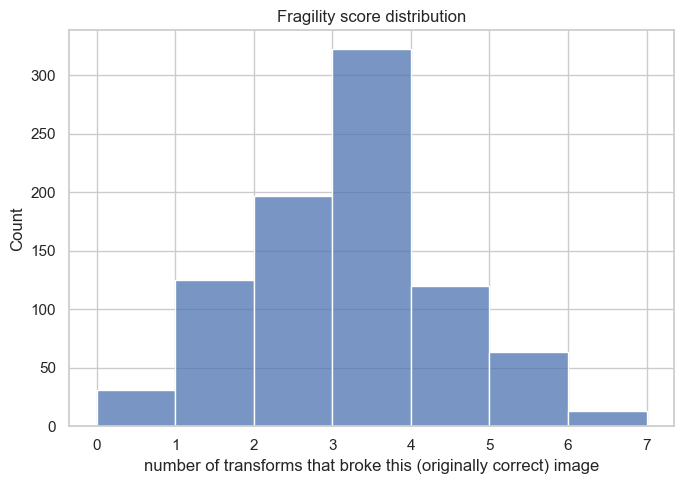

In [2]:
transform_names = [n for n in files if n != "original"]

merged = data["original"][["id", "correct", "margin", "true_label"]].rename(
    columns={"correct": "correct_original", "margin": "original_margin"}
)
for name in transform_names:
    merged = merged.merge(
        data[name][["id", "correct"]].rename(columns={"correct": f"correct_{name}"}),
        on="id"
    )

base = merged[merged["correct_original"]].copy()
base["fragility"] = base[[f"correct_{n}" for n in transform_names]].apply(lambda r: (~r).sum(), axis=1)

print(base["fragility"].value_counts().sort_index())

fig, ax = plt.subplots(figsize=(7, 5))
sns.histplot(base["fragility"], bins=range(0, len(transform_names) + 2), ax=ax)
ax.set_xlabel("number of transforms that broke this (originally correct) image")
ax.set_title("Fragility score distribution")
plt.tight_layout()
plt.show()

# 3. What predicts fragility

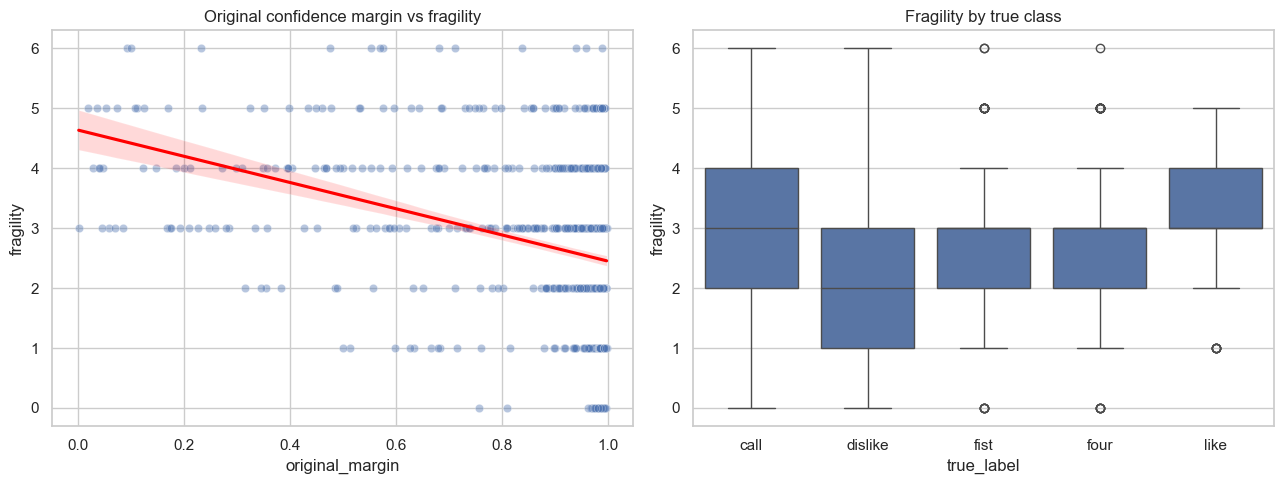

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=base, x="original_margin", y="fragility", alpha=0.4, ax=axes[0])
sns.regplot(data=base, x="original_margin", y="fragility", scatter=False, color="red", ax=axes[0])
axes[0].set_title("Original confidence margin vs fragility")

sns.boxplot(data=base, x="true_label", y="fragility", order=CLASSES, ax=axes[1])
axes[1].set_title("Fragility by true class")
plt.tight_layout()
plt.show()

if "bg_color" in data["original"].columns:
    bg = data["original"][["id", "bg_color"]]
    base2 = base.merge(bg, on="id")
    bg_counts = base2["bg_color"].value_counts()
    valid_bg = bg_counts[bg_counts >= 10].index
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.boxplot(data=base2[base2["bg_color"].isin(valid_bg)], x="bg_color", y="fragility", ax=ax)
    ax.set_title("Fragility by background color (n>=10 categories)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# 4. Error-set overlap between transforms (Jaccard similarity, clustered)

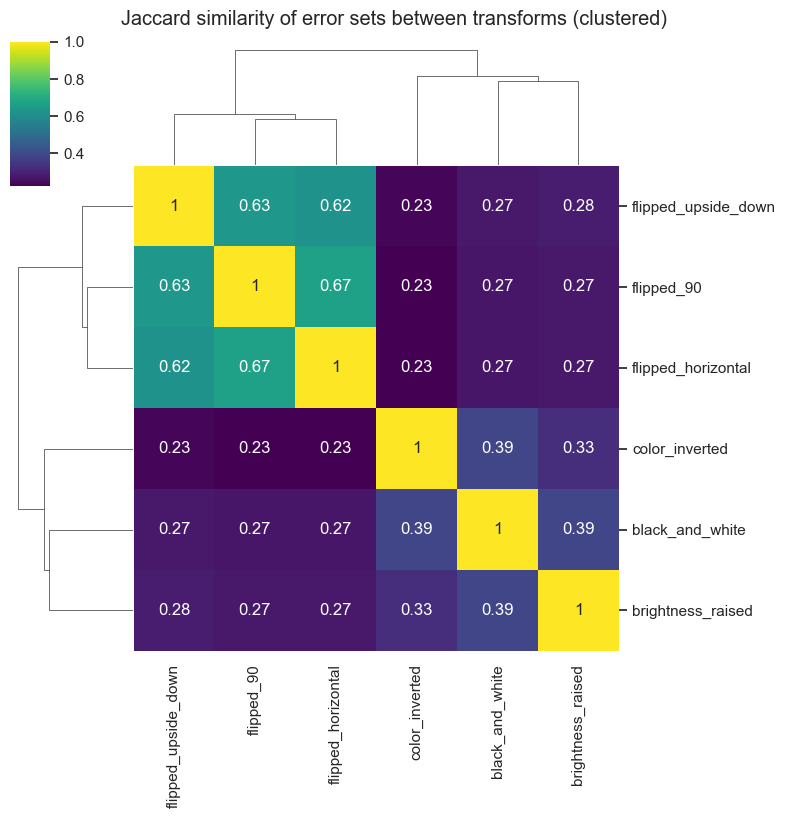

In [4]:
incorrect_sets = {name: set(data[name].loc[~data[name]['correct'], 'id']) for name in transform_names}

jaccard = pd.DataFrame(index=transform_names, columns=transform_names, dtype=float)
for a, b in combinations(transform_names, 2):
    inter = len(incorrect_sets[a] & incorrect_sets[b])
    union = len(incorrect_sets[a] | incorrect_sets[b])
    j = inter / union if union else 0
    jaccard.loc[a, b] = j
    jaccard.loc[b, a] = j
for n in transform_names:
    jaccard.loc[n, n] = 1.0

g = sns.clustermap(jaccard.astype(float), annot=True, cmap="viridis", figsize=(8, 8))
g.fig.suptitle("Jaccard similarity of error sets between transforms (clustered)", y=1.02)
plt.show()

# 5. Quadrant occlusion test (cheap black-box localization)

quadrant    top_left  top_right  bottom_left  bottom_right
true_label                                                
call        0.236346   0.097412     0.148415      0.176306
dislike     0.274400   0.146993     0.216106      0.262444
fist        0.342286   0.345606     0.182516      0.181364
four        0.303400   0.252475     0.151202      0.158898
like        0.204960   0.126347     0.086608      0.054266


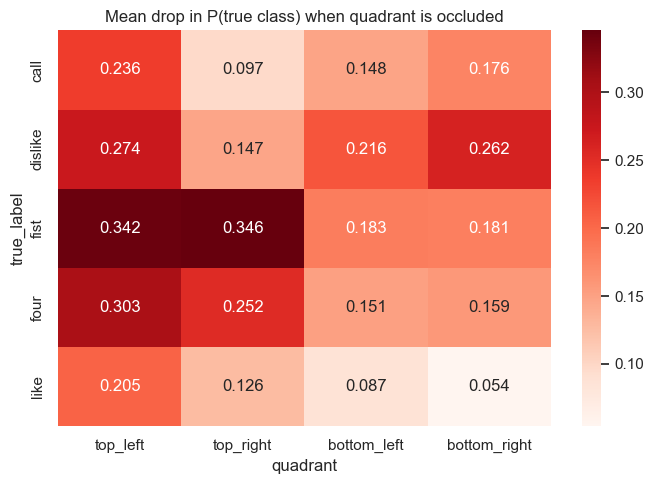

In [5]:
def find_path(img_id, label):
    pattern = os.path.join(DATA_ROOT, f"train_val_{label}", f"{img_id}.*")
    matches = glob.glob(pattern)
    return matches[0] if matches else None

model = AutoModelForImageClassification.from_pretrained(MODEL_PATH).to(device)
model.eval()

to_tensor_normalize = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

def occlude_quadrant(img, quadrant):
    img = img.copy()
    w, h = img.size
    boxes = {
        "top_left": (0, 0, w // 2, h // 2),
        "top_right": (w // 2, 0, w, h // 2),
        "bottom_left": (0, h // 2, w // 2, h),
        "bottom_right": (w // 2, h // 2, w, h),
    }
    box = boxes[quadrant]
    patch = Image.new("RGB", (box[2] - box[0], box[3] - box[1]), (0, 0, 0))
    img.paste(patch, box)
    return img

orig = data["original"]
label2id = {l: i for i, l in enumerate(CLASSES)}
sample = orig[orig["correct"]].groupby("true_label").head(40)  # 40 per class for speed, raise if you have time

records = []
quadrants = ["top_left", "top_right", "bottom_left", "bottom_right"]
for _, row in sample.iterrows():
    path = find_path(row["id"], row["true_label"])
    if path is None:
        continue
    true_idx = label2id[row["true_label"]]
    img = Image.open(path).convert("RGB")
    base_tensor = to_tensor_normalize(img).unsqueeze(0).to(device)
    with torch.no_grad():
        base_prob = F.softmax(model(pixel_values=base_tensor).logits, dim=1)[0, true_idx].item()

    for q in quadrants:
        occ_img = occlude_quadrant(img, q)
        t = to_tensor_normalize(occ_img).unsqueeze(0).to(device)
        with torch.no_grad():
            occ_prob = F.softmax(model(pixel_values=t).logits, dim=1)[0, true_idx].item()
        records.append({"true_label": row["true_label"], "quadrant": q, "prob_drop": base_prob - occ_prob})

occ_df = pd.DataFrame(records)
pivot = occ_df.groupby(["true_label", "quadrant"])["prob_drop"].mean().unstack()[quadrants].reindex(CLASSES)
print(pivot)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="Reds", ax=ax)
ax.set_title("Mean drop in P(true class) when quadrant is occluded")
plt.tight_layout()
plt.show()

# 6. Entropy vs confidence across all conditions

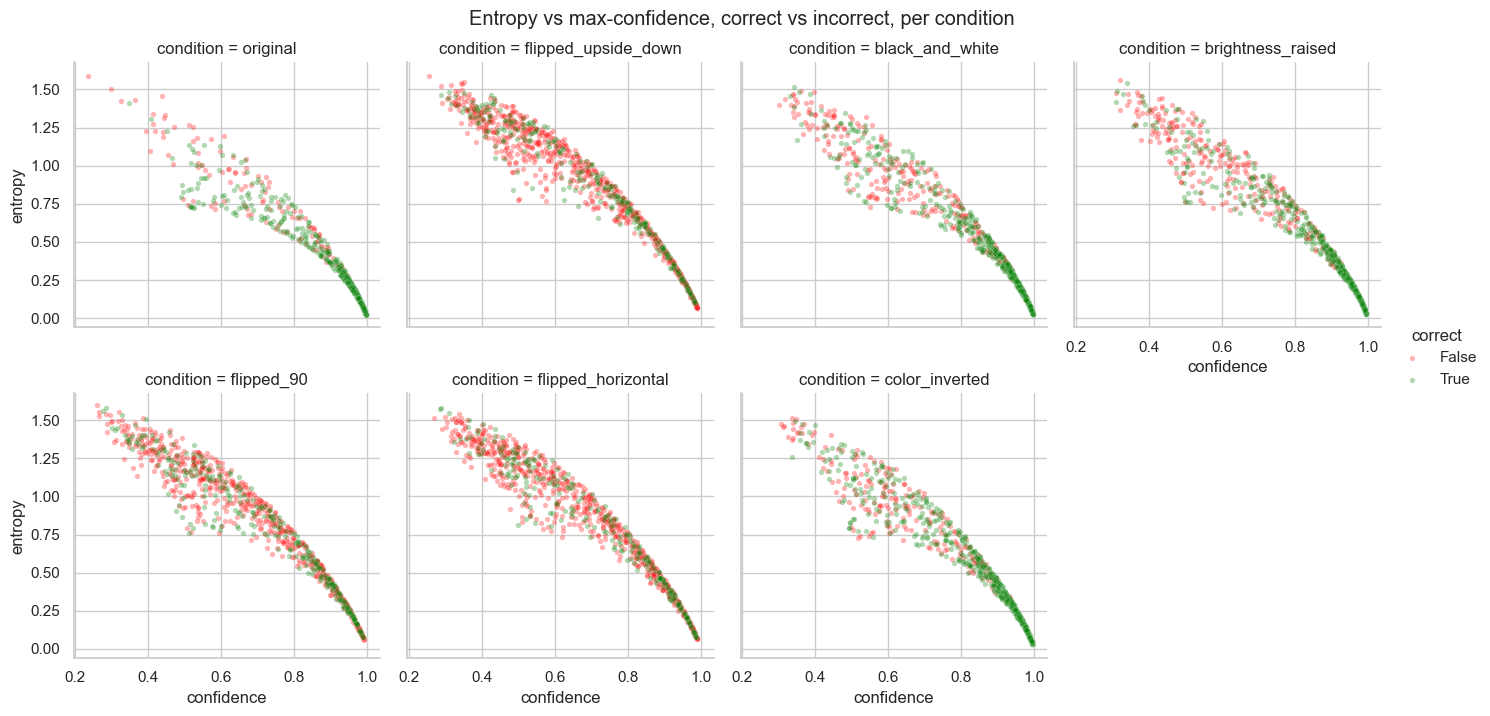

In [6]:
plot_df = pd.concat([
    d.assign(condition=name)[["condition", "entropy", "confidence", "correct"]]
    for name, d in data.items()
], ignore_index=True)

g = sns.FacetGrid(plot_df, col="condition", col_wrap=4, hue="correct",
                   palette={True: "green", False: "red"}, height=3.5)
g.map(sns.scatterplot, "confidence", "entropy", alpha=0.3, s=15)
g.add_legend()
g.fig.suptitle("Entropy vs max-confidence, correct vs incorrect, per condition", y=1.02)
plt.show()